# A03 — Curvas €STR y Euribor 6M con fechas reales

**Objetivos:** construir la curva de descuento €STR y la de proyección Euribor 6M; comprobar que reprecian sus
instrumentos; diagnosticar la interpolación en los forwards; medir el basis; caso del swap a 5 años que sube 20 pb.

**Fuentes:** Hull cap. 7, 9 y 32; Veronesi cap. 2 y 5; Schofield & Bowler cap. 2 y 6. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import (build_curves, bootstrap_estr, bootstrap_euribor6m, discount, zero_rate,
                             forward_rate, ois_par_rate, euribor_swap_par_rate, make_curve, time_from)
from derivlab.dates import spot_date, tenor_end, add_months, year_fraction
from derivlab.swaps import estr_euribor_basis

m = sample_market()
ref, spot = m["ref_date"], spot_date(m["ref_date"])

## 1. Cotizaciones de mercado (sintéticas)

In [2]:
ois = pd.DataFrame(m["ois"], columns=["tenor", "estr_ois"])
swaps = pd.DataFrame(m["swaps"], columns=["tenor", "euribor6m_swap"])
print("€STR ON:", m["estr_on"], " Euribor 6M fixing:", m["euribor6m_fixing"], " FRAs:", m["fras"])
ois.merge(swaps, on="tenor", how="outer").set_index("tenor").loc[
    [t for t in ["1M", "3M", "6M", "9M", "1Y", "18M", "2Y", "3Y", "4Y", "5Y", "6Y", "7Y", "8Y", "9Y",
                 "10Y", "12Y", "15Y", "20Y", "25Y", "30Y"]]]

€STR ON: 0.01874  Euribor 6M fixing: 0.02043  FRAs: [(6, 12, 0.02028), (12, 18, 0.02127)]


,estr_ois,euribor6m_swap
tenor,,
1M,0.01873,NaN
3M,0.01872,NaN
6M,0.01870,NaN
9M,0.01869,NaN
1Y,0.01877,NaN
18M,0.01910,NaN
2Y,0.01960,0.02151
3Y,0.02057,0.02241
4Y,0.02148,0.02326


## 2. Curva €STR

Para un OIS, la pata capitalizada se reduce a $P(t_0) - P(T_n)$, así que la condición par es
$K \sum_i \tau_i P(T_i) = P(t_0) - P(T_n)$. Cada pilar se despeja con un *root-finder*, porque los pagos
intermedios caen entre pilares e interpolan con el pilar nuevo.

In [3]:
estr = bootstrap_estr(ref, m["ois"], m["estr_on"])
pillars = pd.DataFrame({"date": estr["dates"], "df": np.exp(estr["log_dfs"])})
pillars["zero_cont"] = [zero_rate(estr, d) for d in pillars.date]
pillars.round(6)

,date,df,zero_cont
0,2026-10-28,0.999896,0.018999
1,2026-11-30,0.998182,0.018975
2,2027-01-28,0.995135,0.018936
3,2027-04-28,0.990532,0.018872
4,2027-07-28,0.985922,0.018818
5,2027-10-28,0.981223,0.018853
6,2028-04-28,0.971467,0.019211
7,2028-10-30,0.961140,0.019683
8,2029-10-29,0.939678,0.020664
9,2030-10-28,0.917096,0.021591


## 3. Curva Euribor 6M (proyección), descontando en €STR

Swap par: $K \sum_i \tau_i P_{\text{€STR}}(T_i) = \sum_j F^{6M}_j \tau_j P_{\text{€STR}}(T_j)$, donde los
forwards $F^{6M}_j$ salen de la curva que se está construyendo.

In [4]:
eur = bootstrap_euribor6m(ref, estr, m["euribor6m_fixing"], m["fras"], m["swaps"])
print("Pillars:", len(eur["dates"]))
rep = [{"tenor": t, "quote": r, "repriced": euribor_swap_par_rate(estr, eur, spot, t)} for t, r in m["swaps"]]
rep += [{"tenor": t, "quote": r, "repriced": ois_par_rate(estr, spot, t)} for t, r in m["ois"]]
rep = pd.DataFrame(rep)
rep["error_bp"] = (rep.repriced - rep.quote) * 1e4
print(f"CASE max repricing error = {rep.error_bp.abs().max():.2e} bp over {len(rep)} instruments")

Pillars: 18
CASE max repricing error = 1.40e-11 bp over 30 instruments


## 4. Forwards y basis: donde se ven los defectos

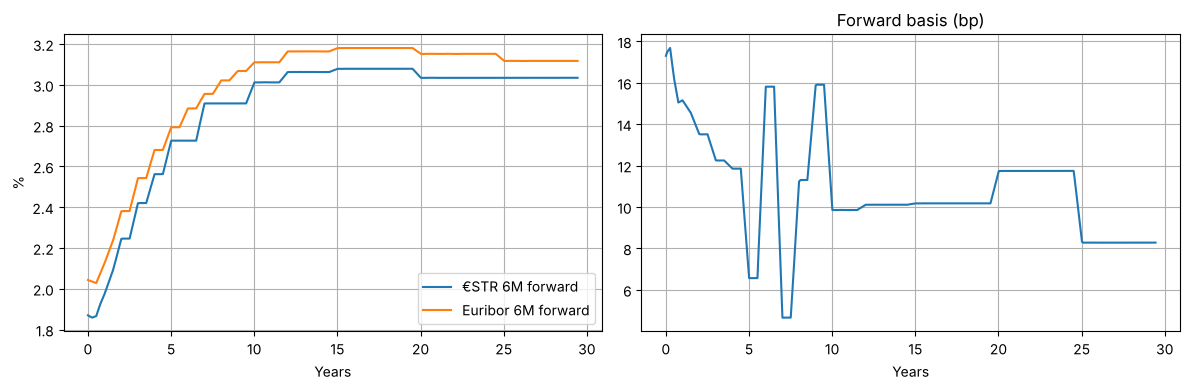

      estr_6m   eur_6m  basis_bp
t                               
1.0   0.01866  0.02028  16.16822
3.0   0.02246  0.02381  13.50909
5.0   0.02562  0.02681  11.85151
6.0   0.02726  0.02792   6.56334
7.0   0.02726  0.02884  15.80850
10.0  0.02909  0.03068  15.90331
20.0  0.03079  0.03181  10.17414
CASE forward basis between 4.5y and 7.5y ranges 4.7 to 15.8 bp


In [5]:
grid = [add_months(spot, k) for k in range(0, 354, 1)]
fw = pd.DataFrame({"start": grid})
fw["t"] = [time_from(ref, d) for d in fw.start]
fw["estr_6m"] = [forward_rate(estr, d, tenor_end(d, "6M")) for d in fw.start]
fw["eur_6m"] = [forward_rate(eur, d, tenor_end(d, "6M")) for d in fw.start]
fw["basis_bp"] = (fw.eur_6m - fw.estr_6m) * 1e4
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(fw.t, fw.estr_6m * 100, label="€STR 6M forward")
ax[0].plot(fw.t, fw.eur_6m * 100, label="Euribor 6M forward")
ax[0].set_xlabel("Years"); ax[0].set_ylabel("%"); ax[0].legend()
ax[1].plot(fw.t, fw.basis_bp); ax[1].set_title("Forward basis (bp)"); ax[1].set_xlabel("Years")
plt.tight_layout(); plt.show()
sel = fw[fw.t.round(0).isin([1, 3, 5, 6, 7, 10, 20])].groupby(fw.t.round(0)).first()
print(sel[["estr_6m", "eur_6m", "basis_bp"]].round(5))
dip = fw[(fw.t > 4.5) & (fw.t < 7.5)].basis_bp
print(f"CASE forward basis between 4.5y and 7.5y ranges {dip.min():.1f} to {dip.max():.1f} bp")

El basis forward cae entre 5 y 7 años y luego se recupera. No es una señal de mercado: la curva €STR tiene
pilares en 5 y 7 años y la de Euribor en 5, 6 y 7. Con forwards constantes por tramos en rejillas distintas,
la resta de ambas curvas dibuja escalones. El ejercicio avanzado lo corrige.

## 5. Interpolación: lineal en log DF frente a lineal en ceros

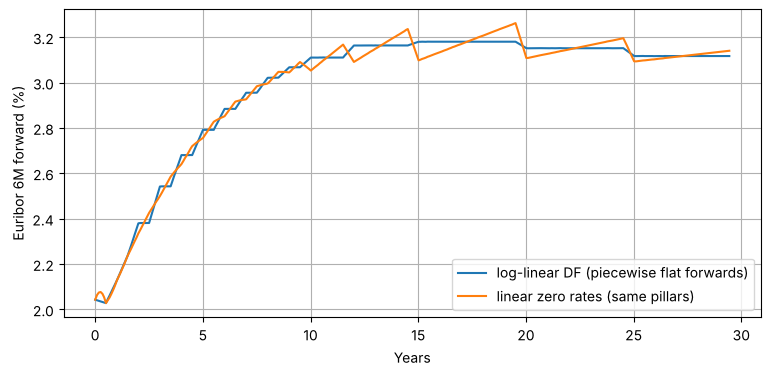

CASE largest month-on-month jump with linear zeros = 2.6 bp


In [6]:
def linear_zero_df(curve, d):
    t = time_from(curve["ref_date"], d)
    times = curve["times"]
    zeros = -curve["log_dfs"] / times
    return np.exp(-np.interp(t, times, zeros) * t)

def fwd_linear_zero(curve, d1, d2):
    return (linear_zero_df(curve, d1) / linear_zero_df(curve, d2) - 1) / year_fraction(d1, d2, "ACT/360")

fw["eur_6m_linear_zero"] = [fwd_linear_zero(eur, d, tenor_end(d, "6M")) for d in fw.start]
plt.plot(fw.t, fw.eur_6m * 100, label="log-linear DF (piecewise flat forwards)")
plt.plot(fw.t, fw.eur_6m_linear_zero * 100, label="linear zero rates (same pillars)")
plt.legend(); plt.xlabel("Years"); plt.ylabel("Euribor 6M forward (%)"); plt.show()
jump = np.abs(np.diff(fw.eur_6m_linear_zero)).max() * 1e4
print(f"CASE largest month-on-month jump with linear zeros = {jump:.1f} bp")

## 6. Basis par €STR / Euribor 6M

In [7]:
basis = pd.DataFrame({"tenor_y": [1, 2, 3, 5, 7, 10, 15, 20, 30]})
basis["par_basis_bp"] = [estr_euribor_basis(estr, eur, spot, add_months(spot, 12 * y)) * 1e4 for y in basis.tenor_y]
print(basis.round(2).to_string(index=False))

 tenor_y  par_basis_bp
       1         16.81
       2         15.87
       3         15.13
       5         13.97
       7         13.23
      10         12.51
      15         11.81
      20         11.50
      30         11.20


## 7. Caso: el swap a 5 años sube 20 pb y el BCE no se ha movido

Un gestor de renta fija pregunta por qué. Se reconstruye la curva con un movimiento típico: el tramo hasta
1 año no cambia, el 2 años sube 5 pb, el 3 años 12, el 4 años 17, el 5 años 20 y el largo 18–19.
Después se miran los forwards anuales de Euribor 6M antes y después.

In [8]:
shock = {"18M": 2, "2Y": 5, "3Y": 12, "4Y": 17, "5Y": 20, "6Y": 19}
def bump(t):
    if t in shock:
        return shock[t]
    months = int(t[:-1]) * (12 if t.endswith("Y") else 1)
    return 0 if months <= 12 else 18
m2 = sample_market()
m2["ois"] = [(t, r + bump(t) * 1e-4) for t, r in m2["ois"]]
m2["swaps"] = [(t, r + bump(t) * 1e-4) for t, r in m2["swaps"]]
estr2, eur2 = build_curves(m2)

rows = []
for k in range(0, 10):
    d1, d2 = add_months(spot, 12 * k), add_months(spot, 12 * (k + 1))
    f1, f2 = forward_rate(eur, d1, d2), forward_rate(eur2, d1, d2)
    rows.append({"forward": f"{k}y-{k + 1}y", "before": f1, "after": f2, "change_bp": (f2 - f1) * 1e4})
fwd_table = pd.DataFrame(rows)
print(fwd_table.to_string(index=False, formatters={"before": "{:.3%}".format, "after": "{:.3%}".format,
                                                  "change_bp": "{:.1f}".format}))
s5_before = euribor_swap_par_rate(estr, eur, spot, "5Y")
s5_after = euribor_swap_par_rate(estr2, eur2, spot, "5Y")
print(f"CASE 5y swap {s5_before:.3%} -> {s5_after:.3%} (+{(s5_after - s5_before) * 1e4:.1f} bp)")
print(f"CASE forward 0y-1y change = {fwd_table.change_bp.iloc[0]:.1f} bp; 4y-5y change = {fwd_table.change_bp.iloc[4]:.1f} bp")

forward before  after change_bp
  0y-1y 2.046% 2.046%       0.0
  1y-2y 2.194% 2.293%       9.9
  2y-3y 2.395% 2.657%      26.3
  3y-4y 2.559% 2.884%      32.5
  4y-5y 2.699% 3.025%      32.6
  5y-6y 2.812% 2.948%      13.6
  6y-7y 2.906% 3.021%      11.5
  7y-8y 2.978% 3.159%      18.1
  8y-9y 3.045% 3.226%      18.2
 9y-10y 3.092% 3.274%      18.2
CASE 5y swap 2.404% -> 2.604% (+20.0 bp)
CASE forward 0y-1y change = 0.0 bp; 4y-5y change = 32.6 bp


**Lectura para el cliente.** El mercado no ha cambiado lo que espera del BCE en los próximos 12 meses. Lo que
ha subido son los tipos esperados a partir del segundo año, o la prima que se exige por prestar a plazo, y eso
concentra la subida en los forwards de 3 a 5 años. Un swap a 5 años es la media de esos forwards.

## 8. Comprobaciones

In [9]:
assert rep.error_bp.abs().max() < 1e-6
assert abs(fwd_table.change_bp.iloc[0]) < 0.5            # short end untouched
assert fwd_table.change_bp.iloc[3:5].min() > 20          # move concentrated in 3y-5y forwards
assert (basis.par_basis_bp > 0).all()
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Con los factores de descuento €STR a 1 y 2 años, calcula el forward 1y1y simple ACT/360.
2. **Intermedio.** Sube 1 pb solo el swap Euribor a 5 años y dibuja cómo cambian los forwards 6M. ¿Por qué suben los de 4 a 5 años y bajan los de 5 a 6?
3. **Avanzado.** Añade cotizaciones OIS a 6, 8 y 9 años interpoladas linealmente entre 5, 7 y 10 años, reconstruye y comprueba si el hueco del basis forward entre 5 y 7 años se reduce.

## Soluciones

In [10]:
d1, d2 = tenor_end(spot, "1Y"), tenor_end(spot, "2Y")
print(f"1y1y = {(discount(estr, d1) / discount(estr, d2) - 1) / year_fraction(d1, d2, 'ACT/360'):.4%}")

1y1y = 2.0440%


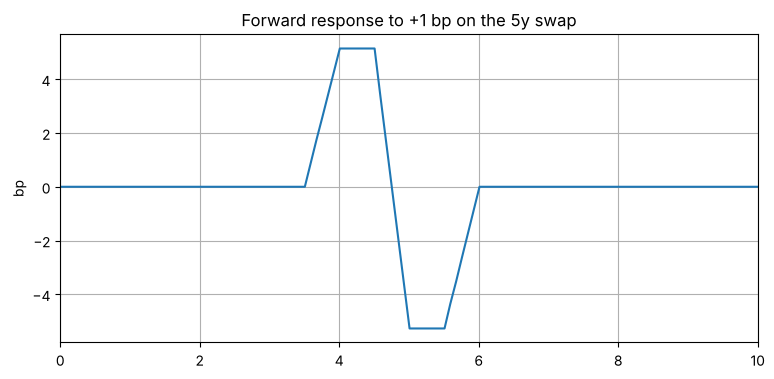

The 5y pillar moves; with piecewise flat forwards the 4y-5y segment absorbs the bump and the 5y-6y segment compensates so that the 6y swap still reprices.


In [11]:
m3 = sample_market()
m3["swaps"] = [(t, r + (1e-4 if t == "5Y" else 0.0)) for t, r in m3["swaps"]]
_, eur3 = build_curves(m3)
dfw = [(forward_rate(eur3, d, tenor_end(d, "6M")) - forward_rate(eur, d, tenor_end(d, "6M"))) * 1e4 for d in fw.start]
plt.plot(fw.t, dfw); plt.xlim(0, 10); plt.ylabel("bp"); plt.title("Forward response to +1 bp on the 5y swap"); plt.show()
print("The 5y pillar moves; with piecewise flat forwards the 4y-5y segment absorbs the bump and the 5y-6y segment compensates so that the 6y swap still reprices.")

In [12]:
m4 = sample_market()
q = dict(m4["ois"])
extra = {"6Y": 0.5 * (q["5Y"] + q["7Y"]), "8Y": q["7Y"] + (q["10Y"] - q["7Y"]) / 3,
         "9Y": q["7Y"] + 2 * (q["10Y"] - q["7Y"]) / 3}
order = ["1M", "3M", "6M", "9M", "1Y", "18M", "2Y", "3Y", "4Y", "5Y", "6Y", "7Y", "8Y", "9Y", "10Y", "12Y", "15Y", "20Y", "30Y"]
q.update(extra)
m4["ois"] = [(t, q[t]) for t in order]
estr4, eur4 = build_curves(m4)
b4 = [(forward_rate(eur4, d, tenor_end(d, "6M")) - forward_rate(estr4, d, tenor_end(d, "6M"))) * 1e4 for d in fw.start]
b4 = pd.Series(b4, index=fw.t)
print(f"Basis range 4.5y-7.5y with aligned pillars: {b4[(b4.index > 4.5) & (b4.index < 7.5)].min():.1f} to "
      f"{b4[(b4.index > 4.5) & (b4.index < 7.5)].max():.1f} bp")

Basis range 4.5y-7.5y with aligned pillars: 8.2 to 16.1 bp
